# 09 — Model Evaluation and Validation
**Day 9 · Phase 4**

This is the **first time the test set is used**. It holds 97 listings of 35 phone models that no model has seen in
any form (not in training, tuning or feature selection).

### Metrics, in plain language
- **MAE (mean absolute error):** the typical size of a miss in rupees. “On average the estimate is off by ₹X.”
- **RMSE (root mean squared error):** like MAE, but squares errors before averaging, so one ₹20k miss counts far more
  than ten ₹2k misses. RMSE ≫ MAE means a few large errors.
- **R² (coefficient of determination):** the share of price variation the model explains. 0.75 = 75 % of the
  differences in price between phones are accounted for.
- **MAPE:** average error as a percentage of the true price. Useful because a ₹2k miss matters more on a ₹7k phone.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from sklearn.base import clone
from sklearn.model_selection import learning_curve
from src.train import load_model_ready_data, xy, group_cv, baseline_models, tuned_models, final_pipeline
from src.evaluate import (holdout_evaluation, regression_metrics, plot_actual_vs_predicted, plot_residuals)

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)
X_te, y_te, g_te = xy(test)
print(f"Train {len(X_tr)} rows / {g_tr.nunique()} models · Test {len(X_te)} rows / {g_te.nunique()} models")

Train 419 rows / 137 models · Test 97 rows / 35 models


## 1. Model comparison framework

In [2]:
candidates = {"Dummy (median)": baseline_models()["Dummy (median)"],
              "Linear Regression": baseline_models()["Linear Regression"],
              **tuned_models()}
holdout, fitted = holdout_evaluation(candidates, X_tr, y_tr, X_te, y_te)

cv = pd.read_csv(PROJECT_ROOT / "reports" / "cv_model_comparison.csv", index_col=0)
cv = cv[cv["stage"] == "tuned"][["cv_MAE", "cv_MAE_std", "cv_R2"]]
base_cv = pd.read_csv(PROJECT_ROOT / "reports" / "baseline_results.csv", index_col=0)[["cv_MAE", "cv_MAE_std", "cv_R2"]]
cv_all = pd.concat([cv, base_cv.loc[["Dummy (median)", "Linear Regression"]]])

comparison = holdout.join(cv_all)[["train_MAE", "train_R2", "cv_MAE", "cv_MAE_std", "cv_R2",
                                   "test_MAE", "test_RMSE", "test_R2", "test_MAPE_%", "fit_time_s"]]
comparison = comparison.sort_values("cv_MAE")
comparison.to_csv(PROJECT_ROOT / "reports" / "model_comparison.csv")
comparison.round(3)

,train_MAE,train_R2,cv_MAE,cv_MAE_std,cv_R2,test_MAE,test_RMSE,test_R2,test_MAPE_%,fit_time_s
model,,,,,,,,,,
Ridge + GB average,"1,217.335",0.973,"2,170.562",615.804,0.847,"2,796.204","5,190.224",0.752,15.578,0.111
Linear Regression,"1,804.392",0.935,"2,329.740",618.036,0.845,"2,935.920","5,784.838",0.692,16.709,0.026
Ridge,"1,804.622",0.934,"2,331.415",621.104,0.845,"2,935.436","5,783.166",0.693,16.706,0.020
Gradient Boosting (tuned),862.271,0.983,"2,468.637",736.110,0.793,"2,969.253","5,348.858",0.737,15.830,0.092
HistGradientBoosting (tuned),505.249,0.993,"2,516.450",856.115,0.780,"2,878.383","5,157.600",0.756,15.583,0.243
Random Forest (tuned),"1,183.370",0.963,"2,806.883","1,023.518",0.756,"3,177.705","6,191.534",0.648,16.504,0.315
Dummy (median),"7,260.921",-0.056,"7,410.806","1,505.196",-0.122,"6,162.567","10,469.419",-0.007,42.256,0.044


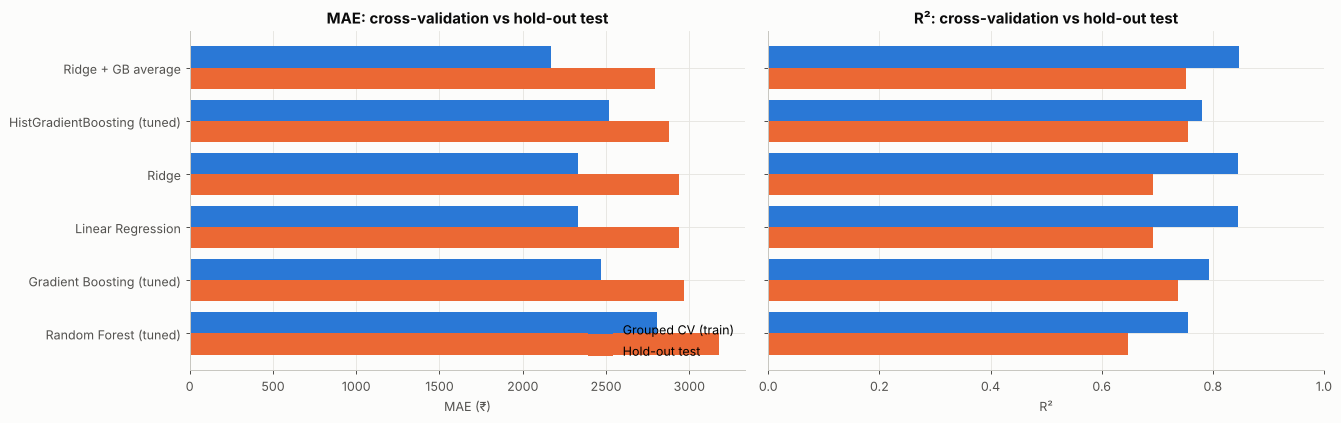

In [3]:
plot = comparison.drop(index="Dummy (median)").sort_values("test_MAE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
yy = np.arange(len(plot))
axes[0].barh(yy + 0.2, plot["cv_MAE"], height=0.4, color=PRIMARY, label="Grouped CV (train)")
axes[0].barh(yy - 0.2, plot["test_MAE"], height=0.4, color=ACCENT, label="Hold-out test")
axes[0].set_yticks(yy, plot.index); axes[0].set(title="MAE: cross-validation vs hold-out test", xlabel="MAE (₹)")
axes[0].legend(loc="lower right")
axes[1].barh(yy + 0.2, plot["cv_R2"], height=0.4, color=PRIMARY, label="Grouped CV (train)")
axes[1].barh(yy - 0.2, plot["test_R2"], height=0.4, color=ACCENT, label="Hold-out test")
axes[1].set_yticks(yy, [""] * len(yy)); axes[1].set(title="R²: cross-validation vs hold-out test", xlabel="R²", xlim=(0, 1))
fig.tight_layout(); save_fig(fig, "eval_model_comparison")

**Interpretation.**
- Every model beats the **Dummy** (test MAE ₹6,163, R² ≈ 0) by a wide margin.
- **Ridge + GB average** has the best test **MAE (₹2,796)** and MAPE (15.6 %), and it was also best in CV.
  Tuned **HistGradientBoosting** is level with it on test RMSE/R² (₹5,158 / 0.756 vs ₹5,190 / 0.752) — a tie on those
  metrics, but HGB was only 4th in CV and has by far the largest train–test gap (§5).
- **Test errors are higher than CV errors for all models** (₹2,796 vs ₹2,171 for the average). The test set is small
  (35 models) and contains several hard premium and “unusual-value” phones (§4).
- On test, Ridge falls behind the boosting models (R² 0.69 vs 0.74–0.76), while in CV it was ahead. This
  **disagreement between CV and test for single models** is a reason to prefer the average, which is at or near the
  top on both.

## 2. How certain is the test result? (bootstrap over phone models)
With only 35 test models, the MAE itself has uncertainty. We resample *models* (not rows, since rows of one model
are related) 2,000 times to get a 95 % interval, and compare the final candidate with Ridge on the same resamples.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
pred = {name: pd.Series(m.predict(X_te), index=X_te.index) for name, m in fitted.items()}
groups = g_te.unique()
by_group = {g: X_te.index[g_te == g] for g in groups}
boot = {"Ridge + GB average": [], "Ridge": [], "Gradient Boosting (tuned)": [], "difference (avg − Ridge)": []}
for _ in range(2000):
    idx = np.concatenate([by_group[g] for g in rng.choice(groups, size=len(groups), replace=True)])
    maes = {k: np.mean(np.abs(y_te.loc[idx] - pred[k].loc[idx])) for k in ["Ridge + GB average", "Ridge", "Gradient Boosting (tuned)"]}
    for k, v in maes.items():
        boot[k].append(v)
    boot["difference (avg − Ridge)"].append(maes["Ridge + GB average"] - maes["Ridge"])
ci = pd.DataFrame({k: {"point": np.mean(v), "2.5%": np.percentile(v, 2.5), "97.5%": np.percentile(v, 97.5)} for k, v in boot.items()}).T
ci["share of resamples where avg is better"] = np.nan
ci.loc["difference (avg − Ridge)", "share of resamples where avg is better"] = np.mean(np.array(boot["difference (avg − Ridge)"]) < 0)
ci.round(3)

,point,2.5%,97.5%,share of resamples where avg is better
Ridge + GB average,"2,810.526","1,707.828","4,163.746",NaN
Ridge,"2,956.891","1,854.797","4,347.972",NaN
Gradient Boosting (tuned),"2,981.530","1,780.051","4,367.779",NaN
difference (avg − Ridge),-146.365,-625.417,259.225,0.740


**Interpretation.** The 95 % interval for the final model's test MAE is wide (**₹1.7k–₹4.2k**): with 35 test models,
one badly-predicted premium phone moves the average a lot. In the **paired** comparison the average beats Ridge in
**74 %** of resamples (mean difference −₹146), but the interval for the difference (−₹625 to +₹259) includes zero, so
the test set alone can't prove it's better. The choice rests on CV + test pointing the same way, and the honest
summary is “typical error around ₹2–3k on unseen phones”, not a precise figure.

## 3. Final model: actual vs predicted and residuals

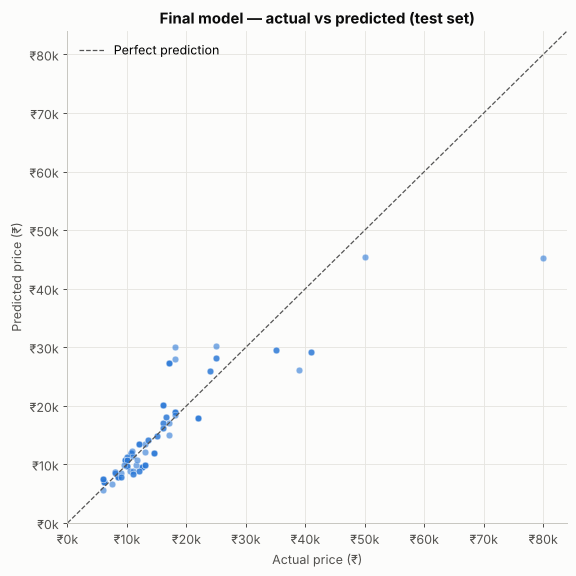

MAE      2,796.204
RMSE     5,190.224
R2           0.752
MAPE_%      15.578
dtype: float64

In [5]:
FINAL = "Ridge + GB average"
final_model = fitted[FINAL]
y_hat = pd.Series(final_model.predict(X_te), index=X_te.index)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
plot_actual_vs_predicted(y_te, y_hat, "Final model — actual vs predicted (test set)", ax=ax)
fig.tight_layout(); save_fig(fig, "eval_actual_vs_predicted")
pd.Series(regression_metrics(y_te, y_hat)).round(3)

Mean residual: ₹346 | median residual: ₹-450
Share of phones within ±₹2,000: 64% | within ±20%: 73%


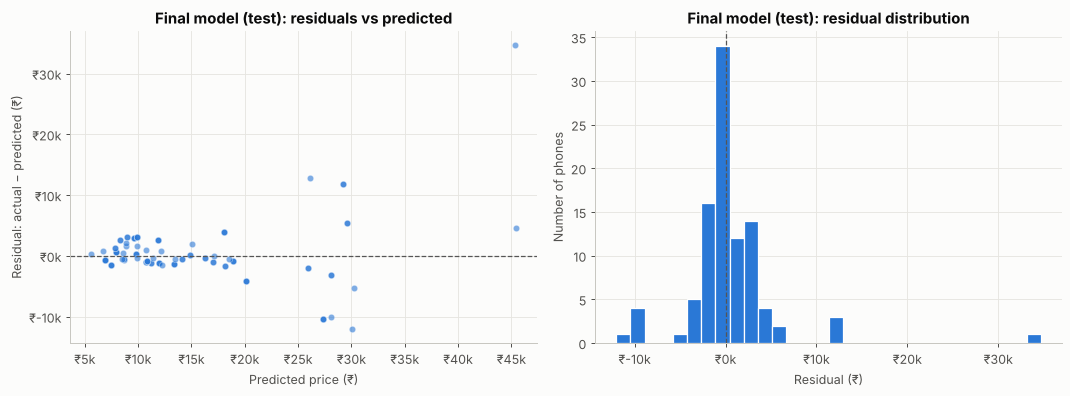

In [6]:
axes = plot_residuals(y_te, y_hat, "Final model (test)")
fig = axes[0].figure; fig.tight_layout(); save_fig(fig, "eval_residuals")
resid = y_te - y_hat
print(f"Mean residual: ₹{resid.mean():,.0f} | median residual: ₹{resid.median():,.0f}")
print(f"Share of phones within ±₹2,000: {(resid.abs() <= 2000).mean():.0%} | within ±20%: {((resid.abs() / y_te) <= 0.2).mean():.0%}")

**Interpretation.**
- Points cluster along the diagonal for the ₹5k–₹30k range, where most phones are. The model works well where the
  data is dense.
- Residuals are centred near zero (no strong overall bias), but the spread **grows with price**
  (heteroscedasticity). That's expected for a log-target model: errors are roughly proportional, so a 15 % miss is
  ₹1k on a budget phone and ₹10k on a flagship.
- **64 % of test phones are within ±₹2,000** of their price and **73 % within ±20 %**. The mean residual is +₹346
  (slight under-prediction overall).
- The largest misses are a handful of phones (see §4), which also explains RMSE (₹5.2k) being much larger than MAE
  (₹2.8k).

## 4. Where does the model fail?

In [7]:
bands = pd.cut(y_te, [0, 10000, 15000, 20000, 30000, 100000], labels=["< ₹10k", "₹10–15k", "₹15–20k", "₹20–30k", "≥ ₹30k"])
by_band = pd.DataFrame({"actual": y_te, "pred": y_hat, "band": bands}).groupby("band", observed=True).apply(
    lambda d: pd.Series({"phones": len(d), "MAE": np.mean(np.abs(d["actual"] - d["pred"])),
                         "MAPE_%": np.mean(np.abs(d["actual"] - d["pred"]) / d["actual"]) * 100,
                         "mean bias (actual − pred)": np.mean(d["actual"] - d["pred"])}), include_groups=False)
by_band.round(1)

,phones,MAE,MAPE_%,mean bias (actual − pred)
band,,,,
< ₹10k,31.000,796.800,10.100,-337.800
₹10–15k,31.000,"1,815.000",14.900,"1,080.300"
₹15–20k,20.000,"3,820.100",22.400,"-3,623.900"
₹20–30k,8.000,"3,425.600",14.600,-430.800
≥ ₹30k,7.000,"12,351.300",24.800,"12,351.300"


In [8]:
worst = test.assign(predicted=y_hat.round(0), error=(y_te - y_hat).round(0),
                    abs_pct_error=((y_te - y_hat).abs() / y_te * 100).round(1))
worst.sort_values("abs_pct_error", ascending=False)[["model", "storage_gb", "ram_gb", "processor", "price", "predicted", "error", "abs_pct_error"]].head(10)

,model,storage_gb,ram_gb,processor,price,predicted,error,abs_pct_error
448,realme X3 SuperZoom,256,6.000,Qualcomm Snapdragon 855+,17999,"30,017.000","-12,018.000",66.800
108,SAMSUNG Galaxy F23 5G,128,6.000,Qualcomm Snapdragon 750G,16999,"27,325.000","-10,326.000",60.700
158,SAMSUNG Galaxy F23 5G,128,6.000,Qualcomm Snapdragon 750G,16999,"27,325.000","-10,326.000",60.700
151,SAMSUNG Galaxy F23 5G,128,6.000,Qualcomm Snapdragon 750G,16999,"27,325.000","-10,326.000",60.700
426,realme X3 SuperZoom,256,NaN,Qualcomm Snapdragon 855,17999,"28,083.000","-10,084.000",56.000
511,SAMSUNG Galaxy S23 5G,256,8.000,Qualcomm Snapdragon 8 Gen 2,79999,"45,328.000","34,671.000",43.300
514,SAMSUNG Galaxy A54 5G,128,8.000,"Exynos 1380, Octa Core",38999,"26,146.000","12,853.000",33.000
490,SAMSUNG Galaxy A54 5G,256,8.000,"Exynos 1380, Octa Core",40999,"29,222.000","11,777.000",28.700
441,SAMSUNG Galaxy A54 5G,256,8.000,"Exynos 1380, Octa Core",40999,"29,222.000","11,777.000",28.700
319,vivo Y16,64,4.000,Mediatek Helio P35,11999,"8,928.000","3,071.000",25.600


**Interpretation.**
- **Budget (< ₹10k):** MAE ₹797 (10 %). **₹10–15k:** ₹1,815 (15 %). These two bands are 64 % of the test set.
- **₹15–20k: over-predicted by ~₹3.6k on average.** The worst cases are the **realme X3 SuperZoom** (Snapdragon
  855/855+, predicted ~₹28–30k, sold at ₹18k) and the **Galaxy F23 5G** (Snapdragon 750G, predicted ₹27k, sold at
  ₹17k). Both carry *older* high-tier chips at clearance prices. The data has **no launch date**, so the model
  can't tell a 2020 flagship from a current one.
- **≥ ₹30k: always under-predicted** (MAE ₹12.4k, bias = MAE). The Galaxy S23 is predicted at ₹45k vs ₹80k, and
  the Galaxy A54 at ₹26–29k vs ₹39–41k. Reasons: very few premium training phones (Apple 5, Google 8 listings), RAM
  missing/capped for premium phones (Days 1 and 3), and brand/series premiums (Samsung S/A-series) that specs alone
  don't capture.
- **Takeaway:** the model is reliable for budget and mainstream phones; for premium phones and older flagships, use
  it only as a rough lower/upper reference.

## 5. Overfitting, underfitting and generalisation
A learning curve trains the final model on growing subsets of the training data (grouped CV) and tracks training vs
validation error.

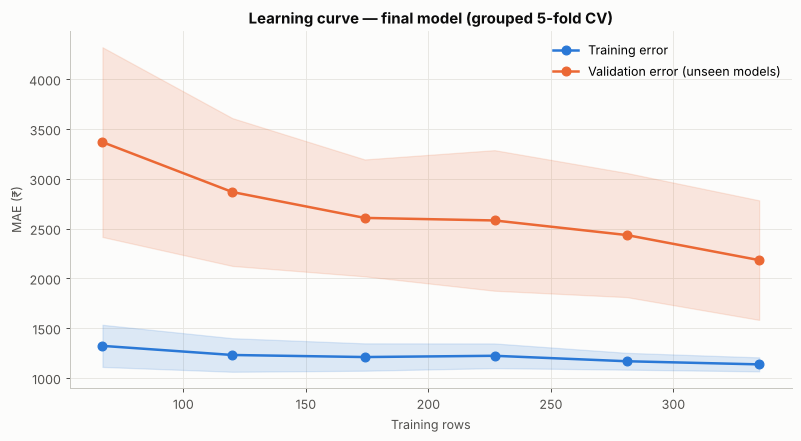

,train rows,train MAE,validation MAE
0,67,"1,323.000","3,370.000"
1,120,"1,232.000","2,868.000"
2,174,"1,211.000","2,609.000"
3,227,"1,224.000","2,583.000"
4,281,"1,169.000","2,436.000"
5,335,"1,137.000","2,184.000"


In [9]:
sizes, tr_scores, va_scores = learning_curve(final_pipeline(), X_tr, y_tr, groups=g_tr, cv=group_cv(),
                                             train_sizes=np.linspace(0.2, 1.0, 6), scoring="neg_mean_absolute_error",
                                             shuffle=True, random_state=RANDOM_STATE, n_jobs=1)
fig, ax = plt.subplots(figsize=(9, 5))
for scores, color, label in [(tr_scores, PRIMARY, "Training error"), (va_scores, ACCENT, "Validation error (unseen models)")]:
    m, s = -scores.mean(1), scores.std(1)
    ax.plot(sizes, m, marker="o", ms=7, lw=2, color=color, label=label)
    ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.15)
ax.set(title="Learning curve — final model (grouped 5-fold CV)", xlabel="Training rows", ylabel="MAE (₹)")
ax.legend(); fig.tight_layout(); save_fig(fig, "eval_learning_curve")
pd.DataFrame({"train rows": sizes, "train MAE": -tr_scores.mean(1), "validation MAE": -va_scores.mean(1)}).round(0)

In [10]:
gap = comparison[["train_MAE", "cv_MAE", "test_MAE"]].drop(index="Dummy (median)").copy()
gap["test / train MAE ratio"] = gap["test_MAE"] / gap["train_MAE"]
gap.sort_values("test / train MAE ratio").round(2)

,train_MAE,cv_MAE,test_MAE,test / train MAE ratio
model,,,,
Ridge,"1,804.620","2,331.410","2,935.440",1.630
Linear Regression,"1,804.390","2,329.740","2,935.920",1.630
Ridge + GB average,"1,217.330","2,170.560","2,796.200",2.300
Random Forest (tuned),"1,183.370","2,806.880","3,177.700",2.690
Gradient Boosting (tuned),862.270,"2,468.640","2,969.250",3.440
HistGradientBoosting (tuned),505.250,"2,516.450","2,878.380",5.700


**Interpretation.**
- **Overfitting:** tuned HistGradientBoosting and GB fit training data very closely (train MAE ₹505 and ₹862) but
  are **5.7× and 3.4× worse** on new models. Ridge has the smallest gap (1.6×) but a higher error floor, a sign of
  mild **underfitting** (a purely additive model can't express interactions like battery × tier).
- The **final average sits in between** (train ₹1,217 → test ₹2,796, 2.3×): some variance remains, but less than
  boosting alone.
- **Learning curve:** training error stays flat (~₹1.1–1.3k) while validation error keeps falling, from ₹3,370 with
  67 rows to ₹2,184 with 335 rows, and hasn't flattened. **More data (especially premium phones) would still improve
  the model**; we're data-limited, not model-limited.

## 6. Final model selection
**Selected: Ridge + Gradient Boosting, equal-weight average, trained on log(price).**

| Criterion | Evidence |
|---|---|
| Best grouped-CV MAE | ₹2,171 (next: Ridge ₹2,331) |
| Best hold-out test MAE | ₹2,796 (R² 0.752; HGB ties on R²/RMSE but overfits most) |
| Consistent across CV and test | first in CV, first on test MAE; single models swap ranks |
| Overfitting | smaller train–test gap than any boosting model |
| Interpretability | still explainable with permutation importance and exact Shapley values (Day 10); Ridge part has readable coefficients |
| Cost | trains in ~0.1 s, no extra dependencies |

**Not selected:** Ridge alone (simpler, but clearly worse on test), tuned GB/HGB (overfit more), Random Forest
(worst tuned model), Decision Tree (looked best only under the leaky random split).

**Deployment model:** the same pipeline and hyperparameters, **refit on all 516 clean rows** (`python -m src.train`).
The test metrics above come from the train-only fit and remain the honest estimate of performance on new phones.

In [11]:
import json
from src.train import main as train_and_save
metadata = train_and_save()

from src.predict import load_model, predict_frame
load_model.cache_clear()
reloaded = load_model()
check = predict_frame(test.head(3))
print("Reloaded model predicts:", check.round(0).tolist())
print(json.dumps({k: metadata[k] for k in ["model", "rows_train", "rows_test", "rows_deploy_fit", "holdout_test_metrics"]}, indent=2))

Hold-out test: MAE ₹2,796 | RMSE ₹5,190 | R² 0.752
Saved /home/claude/mobile-price-prediction/models/final_model.joblib
Reloaded model predicts: [11695.0, 6641.0, 10536.0]
{
  "model": "Ridge + Gradient Boosting (equal-weight average, log target)",
  "rows_train": 419,
  "rows_test": 97,
  "rows_deploy_fit": 516,
  "holdout_test_metrics": {
    "MAE": 2796.204,
    "RMSE": 5190.2237,
    "R2": 0.7525,
    "MAPE_%": 15.5776
  }
}


The saved model reproduces the hold-out metrics above exactly (same split, same seed), and it reloads and predicts
correctly from `models/final_model.joblib`.